### **Import Required Libraries**

In [ ]:
!pip install streamlit -q
!pip install pyngrok==4.1.1 -q
import streamlit as st

url = "https://raw.githubusercontent.com/rafsunsheikh/qs_ranking/main/2024_QS_World_University_Rankings.csv"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 19.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 164.8/164.8 kB 17.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.8/188.8 kB 17.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 41.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.1/82.1 kB 6.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.7/62.7 kB 5.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 341.8/341.8 kB 31.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


### **Load Dataset and EDA before writing the App**

In [3]:
import pandas as pd
url = "/home/mdrafsunsheikh/Desktop/QS_university_ranking_app/Datasets/2024_QS_World_University_Rankings.csv"
qs_dataset = pd.read_csv(url)

In [4]:
qs_dataset.head()

,2024 QS World University Rankings,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28
0,2024,2023,Institution Name,Location,NaN,Classification,NaN,NaN,NaN,NaN,...,NaN,International Students,NaN,International Research Network,NaN,Employment Outcomes,NaN,Sustainability,NaN,Overall
1,RANK,RANK,NaN,NaN,Location,SIZE,FOCUS,RES.,AGE,STATUS,...,RANK,SCORE,RANK,SCORE,RANK,SCORE,RANK,Score,Rank,SCORE
2,rank display,rank display2,institution,location code,location,size,focus,research,age band,status,...,ifr rank,isr score,isr rank,irn score,irn rank,ger score,ger rank,SUS SCORE,SUS RANK,Overall Score
3,1,1,Massachusetts Institute of Technology (MIT),US,United States,M,CO,VH,5,B,...,56,88.2,128,94.3,58,100,4,95.2,51,100.0
4,2,2,University of Cambridge,UK,United Kingdom,L,FC,VH,5,A,...,64,95.8,85,99.9,7,100,6,97.3,33=,99.2


In [5]:
header = qs_dataset.columns
print(header)

Index(['2024 QS World University Rankings', 'Unnamed: 1', 'Unnamed: 2',
       'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7',
       'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12',
       'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16',
       'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20',
       'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24',
       'Unnamed: 25', 'Unnamed: 26', 'Unnamed: 27', 'Unnamed: 28'],
      dtype='object')


In [6]:
df = qs_dataset[["2024 QS World University Rankings", "Unnamed: 28"]]
df.head()

,2024 QS World University Rankings,Unnamed: 28
0,2024,Overall
1,RANK,SCORE
2,rank display,Overall Score
3,1,100.0
4,2,99.2


In [7]:
df.shape

(1500, 2)

In [8]:
df.isna().sum() 

2024 QS World University Rankings    0
Unnamed: 28                          0
dtype: int64

In [9]:
df = df.dropna()

In [10]:
df.head()

,2024 QS World University Rankings,Unnamed: 28
0,2024,Overall
1,RANK,SCORE
2,rank display,Overall Score
3,1,100.0
4,2,99.2


In [11]:
new_df = df.iloc[3:].copy()

In [13]:
new_df.head()

,2024 QS World University Rankings,Unnamed: 28
3,1,100.0
4,2,99.2
5,3,98.9
6,4,98.3
7,5,98.1


In [14]:
new_df.reset_index(drop=True, inplace=True)

In [15]:
new_df.head()

,2024 QS World University Rankings,Unnamed: 28
0,1,100.0
1,2,99.2
2,3,98.9
3,4,98.3
4,5,98.1


In [16]:
new_df["2024 QS World University Rankings"] = pd.to_numeric(new_df["2024 QS World University Rankings"], errors='coerce', downcast='float')
new_df["Unnamed: 28"] = pd.to_numeric(new_df["Unnamed: 28"], errors='coerce', downcast='float')
new_df = new_df.dropna()
new_df.isna().sum()   

2024 QS World University Rankings    0
Unnamed: 28                          0
dtype: int64

In [17]:
new_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 204 entries, 0 to 556
Data columns (total 2 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   2024 QS World University Rankings  204 non-null    float32
 1   Unnamed: 28                        204 non-null    float32
dtypes: float32(2)
memory usage: 3.2 KB


In [18]:
X = new_df.drop("2024 QS World University Rankings", axis = 1)
y = new_df["2024 QS World University Rankings"]

<Axes: >

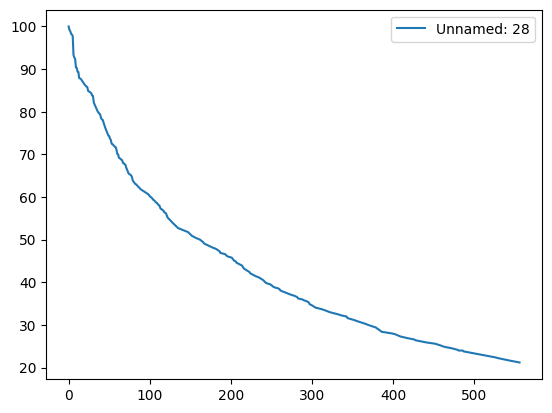

In [19]:
import matplotlib as plt
X.plot()

In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np
random_forest_reg = RandomForestRegressor(random_state=0)
random_forest_reg.fit(X, y.values)

RandomForestRegressor(random_state=0)

In [21]:
y_pred = random_forest_reg.predict(X)
error = np.sqrt(mean_squared_error(y, y_pred))
print(error)

0.8833067959079485


In [22]:
pred = np.array([[48.7]])
print(int(random_forest_reg.predict(pred)))

171


/home/mdrafsunsheikh/Desktop/QS_university_ranking_app/env/lib/python3.10/site-packages/sklearn/base.py:464: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/tmp/ipykernel_8856/3760455868.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print(int(random_forest_reg.predict(pred)))


### **Write the Code into app.py**

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/rafsunsheikh/qs_ranking/main/2023_QS_World_University_Rankings.csv"
qs_dataset = pd.read_csv(url)

df = qs_dataset[["Rank", "score scaled"]]

df = df.dropna()

X = df.drop("Rank", axis = 1)
y = df["Rank"]


from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np
random_forest_reg = RandomForestRegressor(random_state=0)
random_forest_reg.fit(X, y.values)



aca_rep_weight = 0.3
emp_rep_weight = 0.15
fac_stu_ratio_weight = 0.1
cit_per_fac_weight = 0.2
int_fac_ratio_weight = 0.05
int_stu_ratio_weight = 0.05
int_res_net_weight = 0.05
emp_outcome_weight = 0.05
sustainability_weight = 0.05

def score_calculate():

  st.title("QS University Ranking Predictive Dashboard")
  st.write("### Use the sliders to adjust the scores ###")


  aca_rep_score_previous = 29.3
  aca_rep_score = st.slider("Academic Reputation Score", 0.0, 100.0, 29.3)
  if aca_rep_score != aca_rep_score_previous:
    international_reputation_weight = 0.85
    domestic_reputation_weight = 0.15
    international_reputation_score = aca_rep_score * international_reputation_weight
    domestic_reputation_score = aca_rep_score * domestic_reputation_weight
    st.write(f"You have to get {international_reputation_score:.2f}% surveying academician to select this institution internationally within top 30 International university.")
    st.divider()
    st.write(f"You have to get {domestic_reputation_score:.2f}% surveying academician to select this institution domestically within top 10 Domestic University.")
    aca_rep_score_previous = aca_rep_score
    st.divider()
    st.subheader("How to Achieve?")
    st.write("1. Elevate the institution's research quality by fostering a culture of innovation and scholarly excellence.")
    st.write("2. Strengthen academic partnerships by implementing a strategic and collaborative approach.")
    st.write("3. Enhance the institution's strategic impact on the academic landscape.")
    st.write("4. Foster a culture of institutional innovativeness, driving meaningful contributions to education and society.")
    st.write("5. Aspire to rank among the Top 10 Domestic Institutions and the Top 30 International Institutions.")
    st.write("6. Aim for inclusion among the Top 10 Business Schools, both domestically and internationally")
    st.divider()




  emp_rep_score_previous = 26.9
  emp_rep_score = st.slider("Employer Reputation Score", 0.0, 100.0, 26.9)
  if emp_rep_score != emp_rep_score_previous:
    international_emp_reputation_weight = 0.5
    domestic_emp_reputation_weight = 0.5
    international_emp_reputation_score = emp_rep_score * international_emp_reputation_weight
    domestic_emp_reputation_score = emp_rep_score * domestic_emp_reputation_weight
    st.write(f"You have to get {international_emp_reputation_score:.2f}% surveying employer to select this institution internationally within top 30 best International university for producing relevant graduates.")
    st.divider()
    st.write(f"You have to get {domestic_emp_reputation_score:.2f}% surveying employer to select this institution internationally within top 10 best Domestic university for producing relevant graduates.")
    emp_rep_score_previous = emp_rep_score
    st.divider()
    st.subheader("How to Achieve?")
    st.write("1. Ensure the successful employment of the majority of undergraduate students upon completion of their first degree.")
    st.write("2. Foster strong connections with employers to facilitate job placement for our graduates within familiar organizations.")
    st.write("3. Strive for a global reach by enabling graduates to secure positions at renowned domestic and international organizations.")
    st.write("4. Cultivate specialized expertise among graduates in specific academic disciplines.")
    st.write("5. Promote industry-specific specialization among graduates to meet the demands of their respective fields.")
    st.write("6. Aspire to rank among the Top 10 Domestic Universities for producing relevant graduates.")
    st.write("7. Aim for inclusion among the Top 30 International Universities known for producing graduates highly sought after by employers.")
    st.divider()



  fac_stu_ratio_score_previous = 36.5
  fac_stu_ratio_score = st.slider("Faculty Student Ratio Score", 0.0, 100.0, 36.5)
  if fac_stu_ratio_score != fac_stu_ratio_score_previous:
    estimated_fac_stu_ratio = (107.5-fac_stu_ratio_score)/2.5
    st.write(f"To get the score of {fac_stu_ratio_score}, the institution should have Faculty-Student Ratio of 1:{estimated_fac_stu_ratio:.2f}.")
    fac_stu_ratio_score_previous = fac_stu_ratio_score
    st.divider()
    st.subheader("How to Achieve?")
    st.write("1. Increase the availability of academic staff resources to enhance the student experience, including: Teaching, Supervision, Curriculum development, Pastoral support, ensuring a more enriching experience for students.")
    st.write("2. Strive to achieve a more favorable ratio between the number of Full-Time Equivalent Faculty and Full-Time Equivalent students, promoting a more personalized and engaging learning environment.")
    st.divider()





  cit_per_fac_score = st.slider("Citation Per Faculty Score", 0.0, 100.0, 91.4)


  int_fac_ratio_score_previous = 100.0
  int_fac_ratio_score = st.slider("International Faculty Ratio Score", 0.0, 100.0, 100.0)
  if int_fac_ratio_score != int_fac_ratio_score_previous:
    estimated_int_fac_ratio = (103.64 - int_fac_ratio_score)/1.456
    st.write(f"To get the score of {int_fac_ratio_score}, the institution should have International Faculty Ratio of 1:{estimated_int_fac_ratio:.2f}.")
    int_fac_ratio_score_previous = int_fac_ratio_score
    st.divider()
    st.subheader("How to Achieve?")
    st.write("1. Enhance the proportion of international faculty members relative to the overall staff, fostering a more diverse and globally engaged academic environment.")
    st.write("2. Ensure that this increase in international faculty contributes positively to research diversity and collaborative efforts, enriching the academic experience.")
    st.write("3. Strive to increase the number of foreign-national faculty members who contribute to academic teaching, research, or both at the university for a minimum period of at least 3 months, as a proportion of the overall faculty staff.")
    st.divider()


  int_stu_ratio_score_previous = 17.3
  int_stu_ratio_score = st.slider("International Student Ratio Score", 0.0, 100.0, 17.3)
  if int_stu_ratio_score != int_stu_ratio_score_previous:
    estimated_int_stu_ratio = (138.0251 - int_stu_ratio_score)/16.43
    st.write(f"To get the score of {int_stu_ratio_score}, the institution should have international Student Ratio of 1:{estimated_int_stu_ratio:.2f}.")
    int_stu_ratio_score_previous = int_stu_ratio_score
    st.divider()
    st.subheader("How to Achieve?")
    st.write("1. Elevate the proportion of international students relative to the overall student body, promoting greater networking opportunities, cultural exchanges, and a more diverse learning environment.")
    st.write("2. Ensure that this increase in international student enrollment leads to tangible benefits such as enhanced networking, enriched cultural exchanges, and a more diverse and inclusive learning experience.")
    st.write("3. Strive to expand the total number of undergraduate and postgraduate international students, thereby contributing to a globally engaged and diverse campus community.")
    st.divider()




  int_res_net_score = st.slider("International Research Network Score", 0.0, 100.0, 49.2)
  emp_outcome_score = st.slider("Employment Outcome Score", 0.0, 100.0, 12.5)
  sustainability_score = st.slider("Sustainablity Score", 0.0, 100.0, 93.2)

  overall_aca_rep_score = aca_rep_score * aca_rep_weight

  overall_emp_rep_score = emp_rep_score * emp_rep_weight

  overall_fac_stu_ratio_score = fac_stu_ratio_score * fac_stu_ratio_weight

  overall_cit_per_fac_score = cit_per_fac_score * cit_per_fac_weight

  overall_int_fac_ratio_score = int_fac_ratio_score * int_fac_ratio_weight

  overall_int_stu_ratio_score = int_stu_ratio_score * int_stu_ratio_weight

  overall_int_res_net_score = int_res_net_score * int_res_net_weight

  overall_emp_outcome_score = emp_outcome_score * emp_outcome_weight

  overall_sustainability_score = sustainability_score * sustainability_weight


  # return total_overall_score
  ok = st.button("Calculate Score")
  if ok:
    total_overall_score = ( overall_aca_rep_score + overall_emp_rep_score + overall_fac_stu_ratio_score +
                         overall_cit_per_fac_score + overall_int_fac_ratio_score + overall_int_stu_ratio_score +
                          overall_int_res_net_score + overall_emp_outcome_score + overall_sustainability_score)

    pred = np.array([[total_overall_score]])
    rank = random_forest_reg.predict(pred)

    st.subheader(f"The Overall QS Score is {total_overall_score:.2f}")
    st.subheader(f"QS Ranking Outcome is {int(rank)}")

score_calculate()

Writing app.py


In [ ]:
!ls

app.py	sample_data


In [ ]:
!ngrok authtoken 2V45eN4UZSee9iS0eEJUgILbc7S_6BDZKkCCBLGoNLxDWkeH6

Authtoken saved to configuration file: /root/.ngrok2/ngrok.yml


In [ ]:
!ngrok

NAME:
   ngrok - tunnel local ports to public URLs and inspect traffic

DESCRIPTION:
    ngrok exposes local networked services behinds NATs and firewalls to the
    public internet over a secure tunnel. Share local websites, build/test
    webhook consumers and self-host personal services.
    Detailed help for each command is available with 'ngrok help <command>'.
    Open http://localhost:4040 for ngrok's web interface to inspect traffic.

EXAMPLES:
    ngrok http 80                    # secure public URL for port 80 web server
    ngrok http -subdomain=baz 8080   # port 8080 available at baz.ngrok.io
    ngrok http foo.dev:80            # tunnel to host:port instead of localhost
    ngrok http https://localhost     # expose a local https server
    ngrok tcp 22                     # tunnel arbitrary TCP traffic to port 22
    ngrok tls -hostname=foo.com 443  # TLS traffic for foo.com to port 443
    ngrok start foo bar baz          # start tunnels from the configuration file

VERSI

In [ ]:
from pyngrok import ngrok

In [ ]:
!streamlit run app.py&>/dev/null&

In [ ]:
!pgrep streamlit

1749


In [ ]:
!kild 2354

/bin/bash: line 1: kild: command not found


In [ ]:
publ_url = ngrok.connect(port='8501')

In [ ]:
publ_url

'http://acc5-34-138-224-132.ngrok-free.app'

### **Please copy the above url and paste it into a new tab and go. You might find an warning. Please select "Visit Site" and use the app sir.**